In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Caminhos do projeto
ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

INTERIM = ROOT / "data" / "interim"

# Carregar a base já preparada
df_eda = pd.read_parquet(INTERIM / "pns_base_eda.parquet")

print("Dimensões:", df_eda.shape)

display(df_eda.head())


Dimensões: (88456, 11)


,idade,sexo,escolaridade,renda_per_capita,uf,situacao_trabalho,area_residencia,raca_cor,estado_civil,numero_moradores,ativo_lazer
0,55,Mulher,Fundamental incompleto,350,11,Ocupado,Urbana,Branca,Casado(a),6,0
1,19,Mulher,Médio incompleto,250,11,Ocupado,Urbana,Parda,Solteiro(a),4,0
2,45,Mulher,Médio completo,500,11,Ocupado,Urbana,Preta,Solteiro(a),8,0
3,58,Mulher,Sem instrução,324,11,Ocupado,Urbana,Preta,Viúvo(a),1,1
4,28,Mulher,Superior incompleto,0,11,Fora da força de trabalho,Urbana,Parda,Solteiro(a),2,0



# Análise Exploratória de Dados — PNS 2019

## Introdução

Este notebook apresenta a Análise Exploratória de Dados (EDA) da Pesquisa Nacional de Saúde de 2019, realizada pelo IBGE.

### Objetivo
Investigar associações entre características socioeconômicas e demográficas e a prática suficiente de atividade física no lazer.

### Base utilizada
- 88.456 entrevistados com 18 anos ou mais.
- 10 características socioeconômicas e demográficas.
- 1 variável-alvo: `ativo_lazer`.

### Variável-alvo (Y)
- 0: Insuficientemente ativo no lazer.
- 1: Suficientemente ativo no lazer.

As análises utilizam frequências não ponderadas da amostra tratada, sem pretensão de produzir estimativas populacionais.


In [4]:
# Dimensões e estrutura
print("Registros:", len(df_eda))
print("Colunas:", df_eda.shape[1])

# Tipos das variáveis
display(df_eda.dtypes.to_frame("Tipo"))

# Verificar valores ausentes
display(df_eda.isna().sum().to_frame("Ausentes"))

# Distribuição do Y
distribuicao_y = pd.DataFrame(
    {
        "Quantidade": df_eda["ativo_lazer"].value_counts(),
        "Percentual (%)": (
            df_eda["ativo_lazer"].value_counts(normalize=True) * 100
        ).round(2),
    }
)

display(distribuicao_y)


Registros: 88456
Colunas: 11


,Tipo
idade,int64
sexo,str
escolaridade,str
renda_per_capita,int64
uf,str
situacao_trabalho,str
area_residencia,str
raca_cor,str
estado_civil,str
numero_moradores,int64


,Ausentes
idade,0
sexo,0
escolaridade,0
renda_per_capita,0
uf,0
situacao_trabalho,0
area_residencia,0
raca_cor,0
estado_civil,0
numero_moradores,0


,Quantidade,Percentual (%)
ativo_lazer,,
0,63391,71.66
1,25065,28.34



## Diagnóstico e decisões de limpeza

A base original continha 293.726 registros.

### Tratamento de dados ausentes

Identificaram-se ausências estruturais nas perguntas condicionais sobre atividade física. Essas ausências não foram tratadas indiscriminadamente como erros.

Decisões adotadas:
- Preservar entrevistados que declararam não praticar exercícios.
- Reconstruir a situação de trabalho utilizando VDE001 e VDE002.
- Remover 22 registros com renda per capita ausente.
- Remover 10 registros com raça/cor sem categoria válida.
- Considerar entrevistados com 18 anos ou mais.

### Tratamento de outliers

Foi aplicado o método IQR para identificar valores estatisticamente atípicos.

Decisões:
- Remover 48 registros com duração de exercício superior a 6 horas por dia.
- Preservar 18 registros com idade superior a 100,5 anos.
- Preservar 8.397 registros com renda superior a R$ 3.419.
- Preservar 807 registros com mais de 7 moradores.

Os outliers socioeconômicos foram preservados por representarem situações potencialmente legítimas e relevantes para a análise das desigualdades sociais.

### Resultado

A base utilizada na EDA possui 88.456 registros.



### Evolução da base

| Etapa | Registros |
|---|---:|
| Microdados inicialmente extraídos | 293.726 |
| Após filtragem das respostas de atividade física e remoção dos tempos extremos | 90.798 |
| Após remoção de rendas ausentes | 90.776 |
| Após remoção de respostas ignoradas de raça/cor | 90.766 |
| Após selecionar adultos com 18 anos ou mais | 88.456 |

A variável-alvo `ativo_lazer` foi construída no notebook
de extração utilizando as respostas sobre prática,
frequência, duração e modalidade de exercício.

Foram utilizados os critérios definidos no projeto:
150 minutos semanais para atividades classificadas como
moderadas e 75 minutos semanais para atividades
classificadas como vigorosas.


## Análise Univariada

Nesta etapa, investigamos individualmente as características
socioeconômicas e demográficas dos 88.456 entrevistados.

Foram utilizadas estatísticas descritivas, distribuições de
frequência e histogramas para compreender o comportamento
das variáveis numéricas e categóricas.

In [5]:
# Variáveis numéricas
numericas = ["idade", "renda_per_capita", "numero_moradores"]

# Estatísticas descritivas
display(df_eda[numericas].describe().round(2))

# Percentis para investigar a distribuição
display(
    df_eda[numericas]
    .quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.0])
    .round(2)
)


,idade,renda_per_capita,numero_moradores
count,88456.00,88456.00,88456.00
mean,47.19,1613.86,2.91
std,17.12,2833.90,1.49
min,18.00,0.00,1.00
25%,33.00,499.00,2.00
50%,46.00,998.00,3.00
75%,60.00,1667.00,4.00
max,107.00,203196.00,23.00


,idade,renda_per_capita,numero_moradores
0.25,33.0,499.00,2.0
0.50,46.0,998.00,3.0
0.75,60.0,1667.00,4.0
0.90,71.0,3275.00,5.0
0.95,77.0,5150.00,6.0
0.99,86.0,12472.05,7.0
1.00,107.0,203196.00,23.0


In [6]:
categoricas = [
    "sexo",
    "escolaridade",
    "situacao_trabalho",
    "area_residencia",
    "raca_cor",
    "estado_civil",
    "uf",
]

for coluna in categoricas:
    print(f"\nDistribuição: {coluna}")

    tabela = pd.DataFrame(
        {
            "Quantidade": df_eda[coluna].value_counts(),
            "Percentual (%)": (
                df_eda[coluna].value_counts(normalize=True) * 100
            ).round(2),
        }
    )

    display(tabela)



Distribuição: sexo


,Quantidade,Percentual (%)
sexo,,
Mulher,46834,52.95
Homem,41622,47.05



Distribuição: escolaridade


,Quantidade,Percentual (%)
escolaridade,,
Fundamental incompleto,27923,31.57
Médio completo,23355,26.40
Superior completo,13603,15.38
Sem instrução,7630,8.63
Fundamental completo,6526,7.38
Médio incompleto,5466,6.18
Superior incompleto,3953,4.47



Distribuição: situacao_trabalho


...

,Quantidade,Percentual (%)
raca_cor,,
Parda,44612,50.43
Branca,32387,36.61
Preta,10123,11.44
Indígena,669,0.76
Amarela,665,0.75



Distribuição: estado_civil


,Quantidade,Percentual (%)
estado_civil,,
Solteiro(a),38235,43.22
Casado(a),35090,39.67
Viúvo(a),7624,8.62
Divorciado(a) ou separado(a),7507,8.49



Distribuição: uf


,Quantidade,Percentual (%)
uf,,
35,5986,6.77
31,5125,5.79
21,4885,5.52
33,4848,5.48
23,4138,4.68
26,3986,4.51
41,3887,4.39
43,3704,4.19
15,3693,4.17


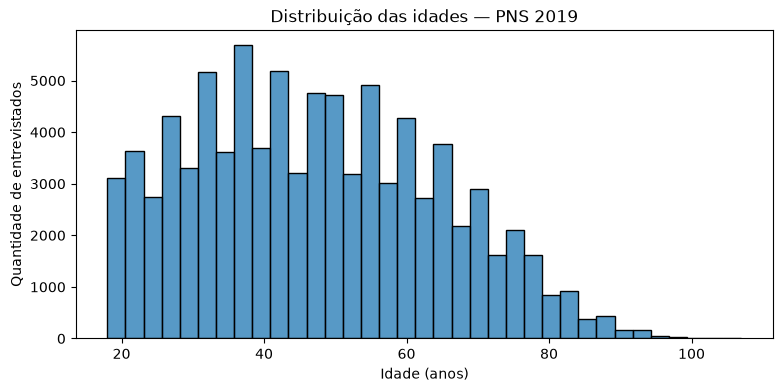

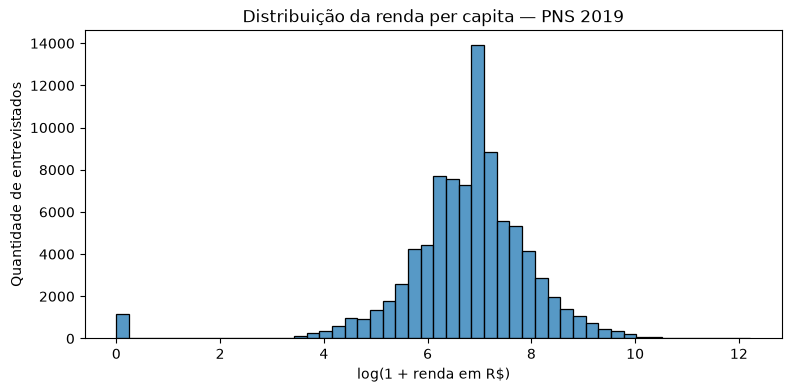

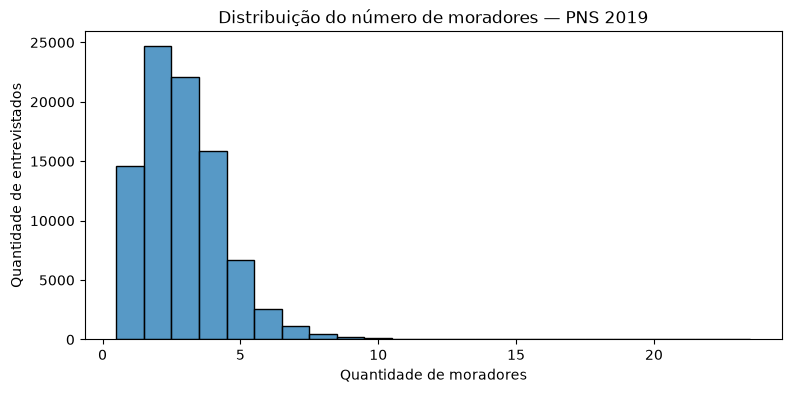

In [7]:
# Idade
plt.figure(figsize=(9, 4))
sns.histplot(df_eda["idade"], bins=35)
plt.title("Distribuição das idades — PNS 2019")
plt.xlabel("Idade (anos)")
plt.ylabel("Quantidade de entrevistados")
plt.show()

# Renda per capita
plt.figure(figsize=(9, 4))
sns.histplot(np.log1p(df_eda["renda_per_capita"]), bins=50)
plt.title("Distribuição da renda per capita — PNS 2019")
plt.xlabel("log(1 + renda em R$)")
plt.ylabel("Quantidade de entrevistados")
plt.show()

# Número de moradores
plt.figure(figsize=(9, 4))
sns.histplot(df_eda["numero_moradores"], discrete=True)
plt.title("Distribuição do número de moradores — PNS 2019")
plt.xlabel("Quantidade de moradores")
plt.ylabel("Quantidade de entrevistados")
plt.show()


### Interpretação dos resultados

A distribuição das idades apresenta maior concentração
de entrevistados adultos e redução da frequência nas
idades mais avançadas.

A renda domiciliar per capita apresenta forte assimetria
à direita, com valores máximos muito superiores à mediana.
A escala logarítmica foi utilizada apenas para melhorar
a visualização dessa distribuição.

O número de moradores apresenta maior concentração em
domicílios com duas a quatro pessoas, sendo menos
frequentes os domicílios muito numerosos.

Entre as características categóricas, destacam-se a
maior proporção de mulheres, residentes urbanos e pessoas
com ensino fundamental incompleto na amostra analisada.

Todas as proporções apresentadas são não ponderadas.


## Análise Bivariada

Nesta etapa, investigamos a associação entre as dez características
socioeconômicas e demográficas e a prática suficiente de atividade
física no lazer.

A variável-alvo `ativo_lazer` possui duas categorias:

- 0: Insuficientemente ativo no lazer.
- 1: Suficientemente ativo no lazer.

Para cada característica, calculamos a quantidade de entrevistados,
a quantidade de suficientemente ativos e o percentual de ativos
em relação ao total de entrevistados do respectivo grupo.

As proporções são calculadas sem ponderação amostral e descrevem
apenas a amostra tratada da PNS 2019.


In [16]:
# Garantir os tipos numéricos
numericas = ["idade", "renda_per_capita", "numero_moradores"]

for coluna in numericas:
    df_eda[coluna] = pd.to_numeric(df_eda[coluna])

df_eda["ativo_lazer"] = pd.to_numeric(df_eda["ativo_lazer"])

# Agrupar as idades
df_eda["faixa_idade"] = pd.cut(
    df_eda["idade"],
    bins=[18, 30, 45, 60, 75, np.inf],
    right=False,
    labels=["18-29", "30-44", "45-59", "60-74", "75+"],
)

# Agrupar renda por quartis
# Agrupar renda por quartis
df_eda["faixa_renda"] = pd.qcut(
    df_eda["renda_per_capita"],
    q=4,
    labels=[
        "Q1 — Até R$ 499",
        "Q2 — R$ 500 a 998",
        "Q3 — R$ 999 a 1.667",
        "Q4 — Acima de R$ 1.667",
    ],
)

# Agrupar número de moradores
df_eda["faixa_moradores"] = pd.cut(
    df_eda["numero_moradores"],
    bins=[0, 1, 2, 4, np.inf],
    labels=["1", "2", "3-4", "5+"],
)

# Ordenar os níveis de escolaridade
ordem_escolaridade = [
    "Sem instrução",
    "Fundamental incompleto",
    "Fundamental completo",
    "Médio incompleto",
    "Médio completo",
    "Superior incompleto",
    "Superior completo",
]

df_eda["escolaridade"] = pd.Categorical(
    df_eda["escolaridade"], categories=ordem_escolaridade, ordered=True
)

print("Agrupamentos criados com sucesso!")


Agrupamentos criados com sucesso!


In [17]:
def analisar_atividade(df, coluna):

    resultado = df.groupby(coluna, observed=True, dropna=False).agg(
        entrevistados=("ativo_lazer", "size"),
        ativos=("ativo_lazer", "sum"),
        percentual_ativos=("ativo_lazer", "mean"),
    )

    resultado["percentual_ativos"] = (
        resultado["percentual_ativos"] * 100
    ).round(2)

    return resultado


# As dez características selecionadas
variaveis_eda = [
    "faixa_idade",
    "sexo",
    "escolaridade",
    "faixa_renda",
    "uf",
    "situacao_trabalho",
    "area_residencia",
    "raca_cor",
    "estado_civil",
    "faixa_moradores",
]

# Armazenar os resultados
resultados_bivariados = {}

for coluna in variaveis_eda:
    resultados_bivariados[coluna] = analisar_atividade(df_eda, coluna)

    print(f"\nAtividade física por {coluna}")
    display(resultados_bivariados[coluna])



Atividade física por faixa_idade


,entrevistados,ativos,percentual_ativos
faixa_idade,,,
18-29,15377,6058,39.4
30-44,26728,8705,32.57
45-59,23637,6046,25.58
60-74,16755,3558,21.24
75+,5959,698,11.71



Atividade física por sexo


,entrevistados,ativos,percentual_ativos
sexo,,,
Homem,41622,12825,30.81
Mulher,46834,12240,26.13



Atividade física por escolaridade


...

,entrevistados,ativos,percentual_ativos
raca_cor,,,
Amarela,665,223,33.53
Branca,32387,9719,30.01
Indígena,669,169,25.26
Parda,44612,12091,27.1
Preta,10123,2863,28.28



Atividade física por estado_civil


,entrevistados,ativos,percentual_ativos
estado_civil,,,
Casado(a),35090,9699,27.64
Divorciado(a) ou separado(a),7507,2248,29.95
Solteiro(a),38235,11795,30.85
Viúvo(a),7624,1323,17.35



Atividade física por faixa_moradores


,entrevistados,ativos,percentual_ativos
faixa_moradores,,,
1,14636,4042,27.62
2,24685,6698,27.13
3-4,37952,11316,29.82
5+,11183,3009,26.91


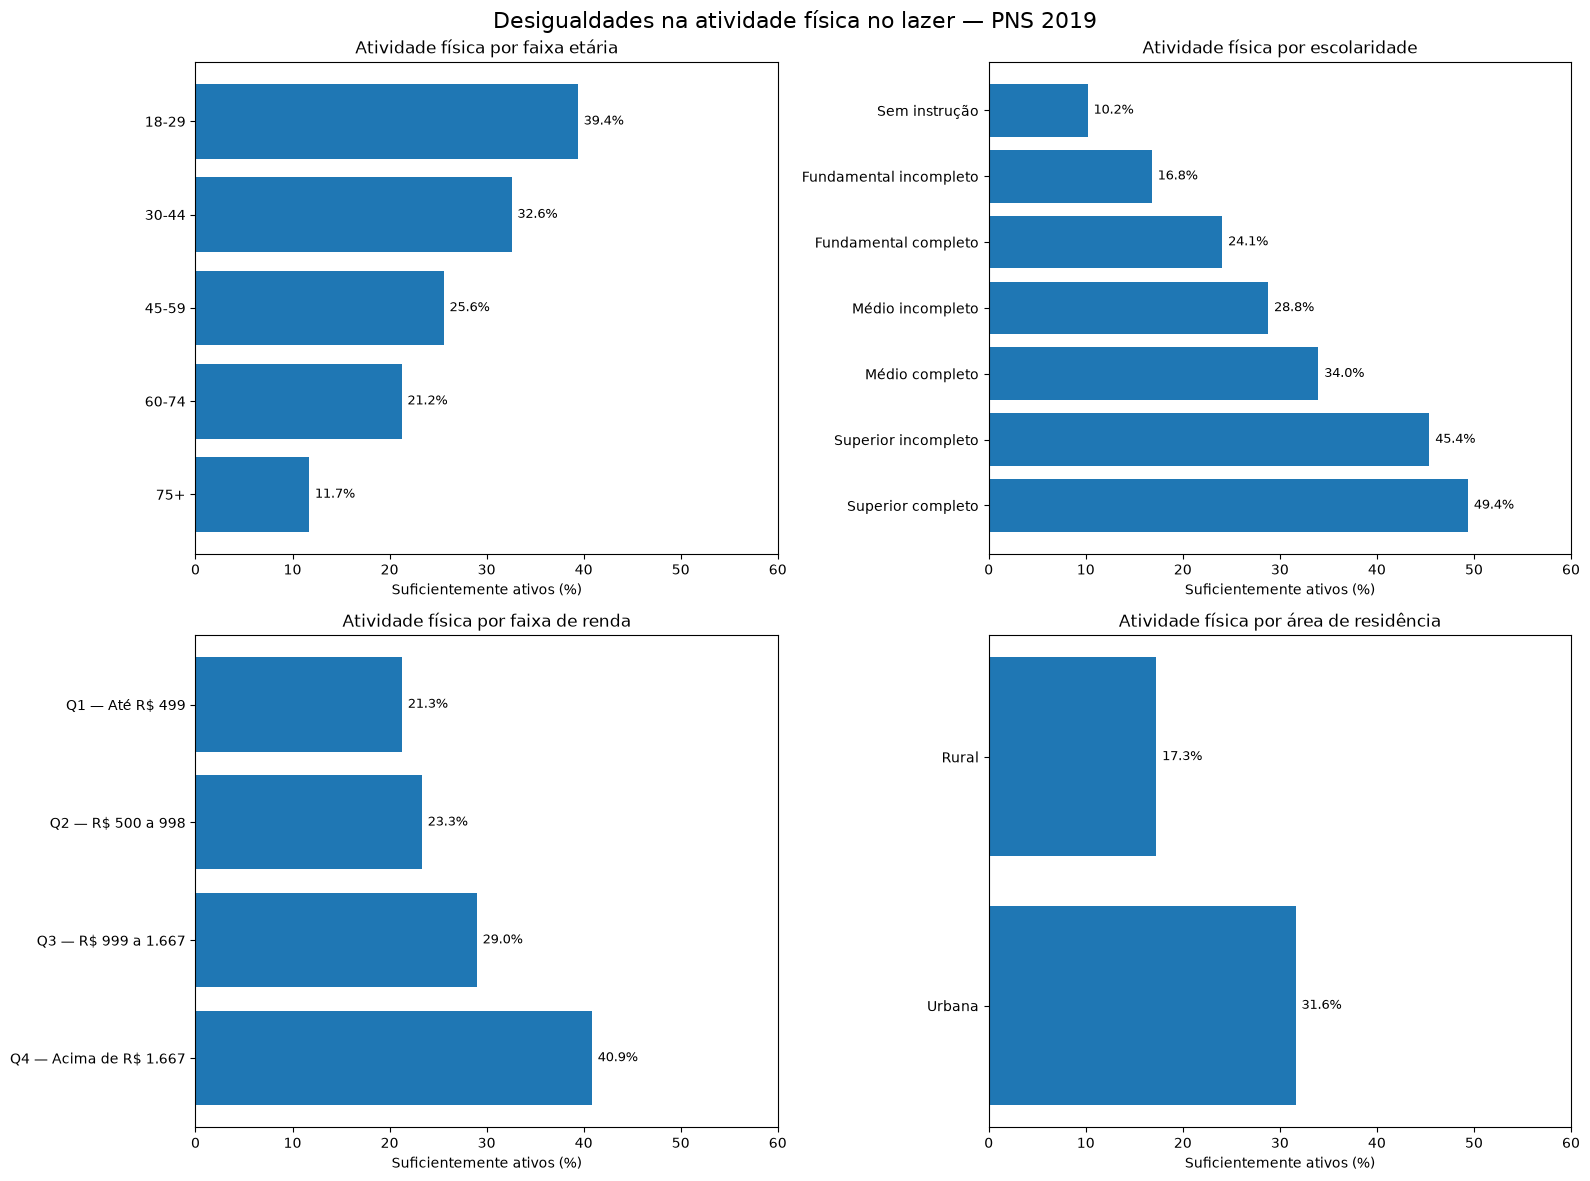

In [18]:
variaveis_grafico = {
    "faixa_idade": "Atividade física por faixa etária",
    "escolaridade": "Atividade física por escolaridade",
    "faixa_renda": "Atividade física por faixa de renda",
    "area_residencia": "Atividade física por área de residência",
}

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for ax, (coluna, titulo) in zip(axes.flat, variaveis_grafico.items()):

    tabela = resultados_bivariados[coluna]

    ax.barh(tabela.index.astype(str), tabela["percentual_ativos"])

    ax.set_title(titulo)
    ax.set_xlabel("Suficientemente ativos (%)")
    ax.set_xlim(0, 60)

    # Colocar o primeiro grupo no topo
    ax.invert_yaxis()

    for i, valor in enumerate(tabela["percentual_ativos"]):
        ax.text(valor + 0.6, i, f"{valor:.1f}%", va="center", fontsize=9)

plt.suptitle(
    "Desigualdades na atividade física no lazer — PNS 2019", fontsize=16
)

plt.tight_layout()
plt.show()



### Interpretação dos resultados bivariados

A análise identificou diferenças importantes na proporção de
entrevistados suficientemente ativos no lazer.

**Escolaridade:** o percentual de suficientemente ativos aumenta
de 10,20% entre pessoas sem instrução para 49,39% entre aquelas
com ensino superior completo.

**Renda:** a menor faixa de renda apresentou 21,28% de
suficientemente ativos, enquanto a maior apresentou 40,85%.

**Idade:** observou-se redução progressiva da proporção de
suficientemente ativos conforme o aumento da idade, passando
de 39,40% entre 18 e 29 anos para 11,71% entre pessoas
de 75 anos ou mais.

**Área de residência:** os moradores de áreas urbanas
apresentaram 31,63% de atividade física suficiente,
contra 17,27% dos residentes rurais.

Os resultados indicam associações entre características
socioeconômicas e demográficas e a prática suficiente de
atividade física no lazer.

Entretanto, essas associações não demonstram causalidade.
As porcentagens correspondem à amostra tratada, sem
aplicação dos pesos amostrais.



## Análise Multivariada

Nesta etapa, investigamos a relação simultânea entre idade,
renda domiciliar per capita e prática suficiente de atividade
física no lazer.

O objetivo é verificar se a associação observada entre renda
e atividade física também aparece dentro das diferentes faixas
etárias da amostra.

Para isso, calculamos a proporção de suficientemente ativos
em cada combinação de faixa etária e quartil de renda.


In [19]:
# Agrupar por faixa etária e quartil de renda
analise_multivariada = (
    df_eda.groupby(["faixa_idade", "faixa_renda"], observed=True)
    .agg(
        entrevistados=("ativo_lazer", "size"),
        percentual_ativos=("ativo_lazer", "mean"),
    )
    .reset_index()
)

# Converter a proporção em percentual
analise_multivariada["percentual_ativos"] *= 100

# Criar matriz para o gráfico
matriz_idade_renda = analise_multivariada.pivot(
    index="faixa_idade", columns="faixa_renda", values="percentual_ativos"
)

display(matriz_idade_renda.round(2))


faixa_renda,Q1 — Até R$ 499,Q2 — R$ 500 a 998,Q3 — R$ 999 a 1.667,Q4 — Acima de R$ 1.667
faixa_idade,,,,
18-29,30.22,38.26,43.81,57.83
30-44,21.99,28.13,36.35,50.42
45-59,15.24,20.11,25.83,40.01
60-74,13.47,14.99,18.62,32.32
75+,4.41,8.98,11.26,16.9


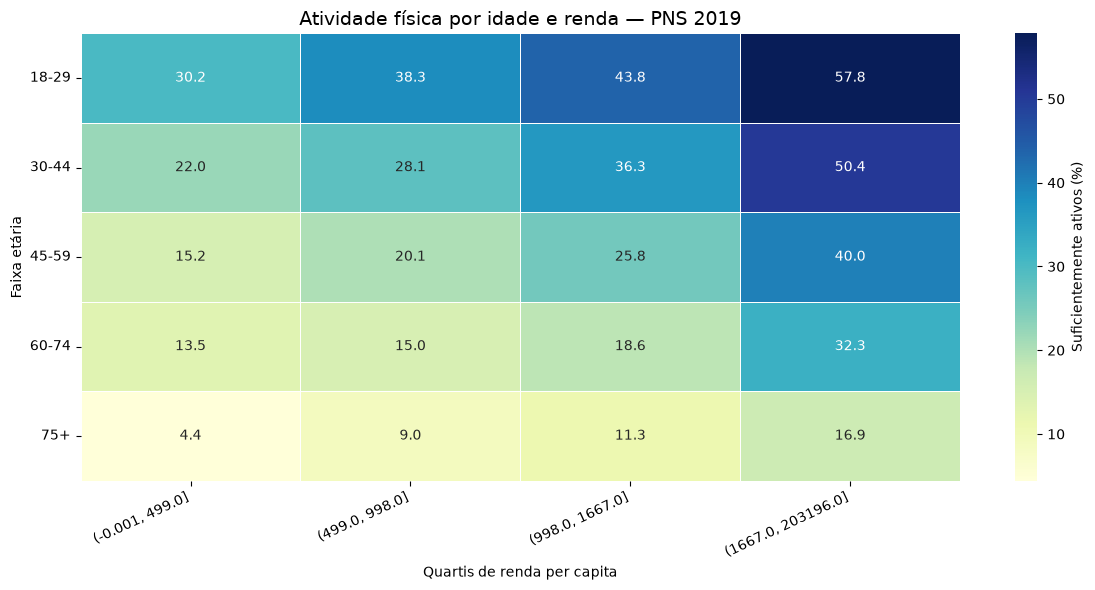

In [13]:
# Garantir que a matriz utilize números reais
matriz_idade_renda = pd.DataFrame(
    matriz_idade_renda.to_numpy(dtype=float, na_value=np.nan),
    index=matriz_idade_renda.index,
    columns=matriz_idade_renda.columns,
)

# Criar mapa de calor
plt.figure(figsize=(12, 6))

sns.heatmap(
    matriz_idade_renda,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Suficientemente ativos (%)"},
)

plt.title("Atividade física por idade e renda — PNS 2019", fontsize=14)

plt.xlabel("Quartis de renda per capita")
plt.ylabel("Faixa etária")

plt.xticks(rotation=25, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()



### Interpretação dos resultados

A análise multivariada identificou diferenças consistentes
na proporção de entrevistados suficientemente ativos entre
as faixas de renda, mesmo quando considerada a idade.

Em todas as faixas etárias, os entrevistados pertencentes
ao quartil de maior renda apresentaram proporções superiores
de atividade física suficiente em comparação com aqueles
pertencentes ao quartil de menor renda.

Entre os entrevistados de 18 a 29 anos, a proporção variou
de aproximadamente 30,2% no menor quartil de renda para
57,8% no maior.

Entre os entrevistados com 75 anos ou mais, os percentuais
foram de aproximadamente 4,4% e 16,9%, respectivamente.

Esses resultados reforçam a associação entre condições
socioeconômicas e atividade física no lazer na amostra
analisada, mas não permitem estabelecer causalidade.



## Correlações e Redundâncias

Nesta etapa, investigamos possíveis associações e redundâncias
entre as características socioeconômicas e demográficas.

Foram utilizadas duas medidas:

- Correlação de Spearman para variáveis numéricas.
- V de Cramér para variáveis categóricas.

O objetivo é identificar características fortemente relacionadas
e avaliar a presença de possíveis informações redundantes,
sem realizar seleção de atributos nesta etapa.


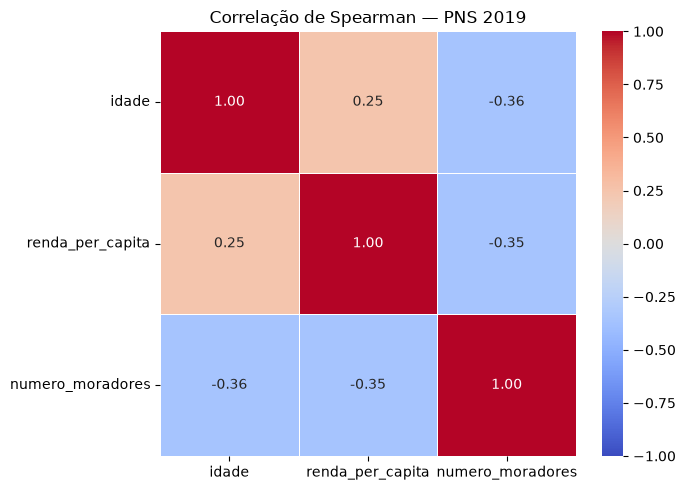

In [20]:
numericas = ["idade", "renda_per_capita", "numero_moradores"]

matriz_spearman = df_eda[numericas].corr(method="spearman")

plt.figure(figsize=(7, 5))

sns.heatmap(
    matriz_spearman,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
)

plt.title("Correlação de Spearman — PNS 2019")

plt.tight_layout()
plt.show()


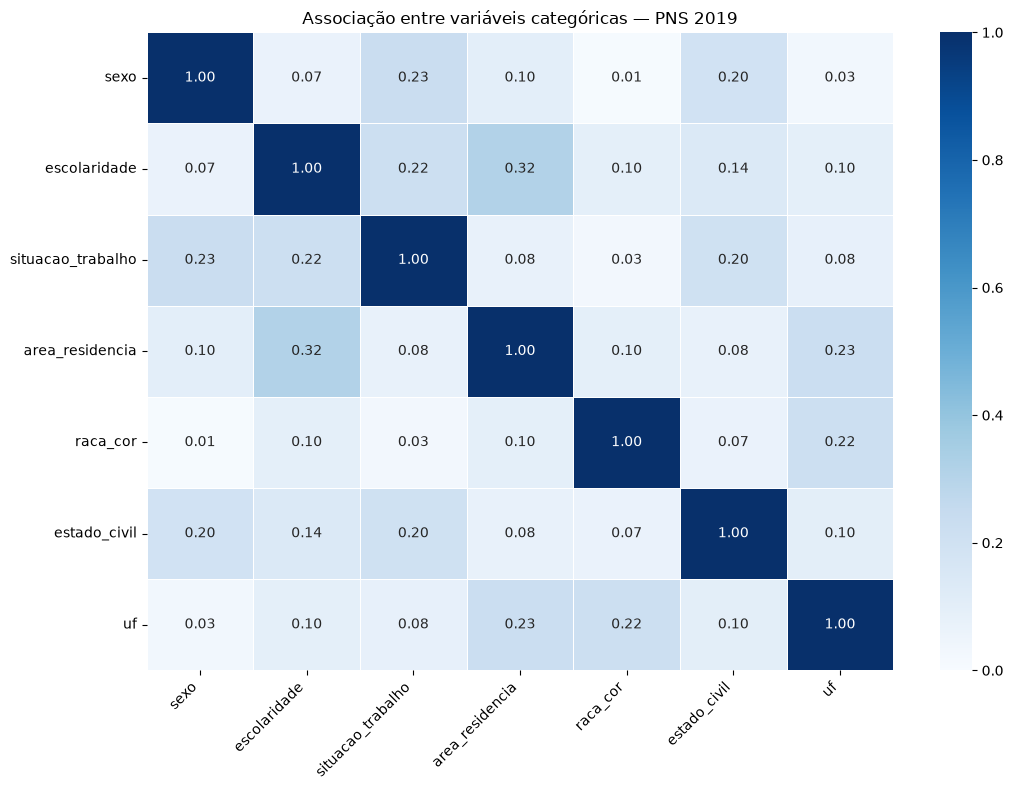

,Variável 1,Variável 2,V de Cramér
7,escolaridade,area_residencia,0.316022
1,sexo,situacao_trabalho,0.231907
17,area_residencia,uf,0.225636
6,escolaridade,situacao_trabalho,0.219738
19,raca_cor,uf,0.219411
13,situacao_trabalho,estado_civil,0.203184
4,sexo,estado_civil,0.195275
9,escolaridade,estado_civil,0.142010
20,estado_civil,uf,0.104143
2,sexo,area_residencia,0.099727


In [21]:
from itertools import combinations

from scipy.stats import chi2_contingency

categoricas = [
    "sexo",
    "escolaridade",
    "situacao_trabalho",
    "area_residencia",
    "raca_cor",
    "estado_civil",
    "uf",
]


def cramers_v(x, y):
    tabela = pd.crosstab(x, y)
    n = tabela.to_numpy().sum()
    r, k = tabela.shape

    if n <= 1 or min(r, k) < 2:
        return np.nan

    chi2 = chi2_contingency(tabela, correction=False)[0]

    phi2 = chi2 / n

    # Correção de viés
    phi2_corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))

    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)

    denominador = min(r_corr - 1, k_corr - 1)

    return np.sqrt(phi2_corr / denominador)


matriz_cramer = pd.DataFrame(
    np.eye(len(categoricas)), index=categoricas, columns=categoricas
)

for var1, var2 in combinations(categoricas, 2):
    valor = cramers_v(df_eda[var1], df_eda[var2])

    matriz_cramer.loc[var1, var2] = valor
    matriz_cramer.loc[var2, var1] = valor

plt.figure(figsize=(11, 8))

sns.heatmap(
    matriz_cramer,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    linewidths=0.5,
)

plt.title("Associação entre variáveis categóricas — PNS 2019")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# Maiores associações entre pares diferentes
associacoes = []

for var1, var2 in combinations(categoricas, 2):
    associacoes.append(
        {
            "Variável 1": var1,
            "Variável 2": var2,
            "V de Cramér": matriz_cramer.loc[var1, var2],
        }
    )

tabela_associacoes = pd.DataFrame(associacoes).sort_values(
    "V de Cramér", ascending=False
)

display(tabela_associacoes.head(10))



### Interpretação das correlações

A correlação de Spearman apresentou associações fracas a
moderadas entre idade, renda per capita e número de moradores.

A maior associação numérica, em valor absoluto, ocorreu
entre idade e número de moradores, com aproximadamente -0,36.

Na análise categórica, utilizando o V de Cramér com correção
de viés, a maior associação ocorreu entre escolaridade
e área de residência (urbana/rural), com aproximadamente 0,316.

Outras associações relevantes foram:
- Sexo × Situação de trabalho: 0,232.
- Área de residência × UF: 0,226.
- Escolaridade × Situação de trabalho: 0,220.
- Raça/cor × UF: 0,219.

Não foram identificadas associações suficientemente fortes
para justificar a exclusão de características por redundância.

Portanto, decidiu-se preservar as dez variáveis preditoras
nesta fase da análise.

A avaliação de diferentes subconjuntos de atributos será
realizada posteriormente na etapa experimental.



## Conclusão da Análise Exploratória

A Análise Exploratória de Dados foi realizada sobre uma base
tratada de 88.456 entrevistados adultos da Pesquisa Nacional
de Saúde de 2019.

Foram investigadas distribuições, valores ausentes, outliers,
associações socioeconômicas e possíveis redundâncias entre
as características selecionadas.

A análise identificou diferenças expressivas na prática
suficiente de atividade física no lazer segundo escolaridade,
renda, idade e área de residência.

A análise multivariada demonstrou que os entrevistados
pertencentes às maiores faixas de renda apresentaram maiores
proporções de atividade física suficiente em todas as
faixas etárias consideradas.

Os resultados das correlações numéricas e das associações
categóricas não indicaram redundâncias suficientemente
fortes para justificar a exclusão de variáveis nesta etapa.

Assim, as dez características socioeconômicas e demográficas
foram preservadas para a avaliação experimental posterior.

Os resultados descrevem a amostra tratada, sem ponderação
amostral, e não devem ser interpretados como relações causais
ou estimativas representativas de toda a população brasileira.

A EDA fornece, portanto, uma base descritiva para a próxima
etapa do projeto: investigação das estratégias de
pré-processamento e avaliação do algoritmo KNN.
